# NBA Game Outcome Prediction

Dataset: https://www.kaggle.com/datasets/nathanlauga/nba-games?select=teams.csv

In [1]:
import pandas as pd
import numpy as np
import networkx as nx

In [2]:
games = pd.read_csv("/Users/leowiemelt/Desktop/CSE150A/data/games.csv")
teams = pd.read_csv("/Users/leowiemelt/Desktop/CSE150A/data/teams.csv")
ranking = pd.read_csv("/Users/leowiemelt/Desktop/CSE150A/data/ranking.csv")

In [3]:
# PointDiff: point differential (home - away), binned into large loss/win (+-10 points) and close games
# Will NOT be included as a predictor in the model, just to see causal effects of other vars
games["PointDiff"] = games["PTS_home"] - games["PTS_away"]

games["PointDiff_bin"] = pd.cut(
    games["PointDiff"],
    bins=[-np.inf, -10, 10, np.inf],
    labels=["BigLoss", "Close", "BigWin"]
)

### Data Preprocessing and Thresholding


In [4]:
# Target variable: HOME_TEAM_WINS (bool)
games["HomeWin"] = games["HOME_TEAM_WINS"].astype(int)

In [5]:
# # Home and Away win percentage: bin into weak (<=40%), average (40-60%), and strong (>=60%)
# # Standard cutoffs commonly used in basketball analytics, reduces noise of using raw win %
# # WinPctDiff = HomeWinPct - AwayWinPct, binned into AwayStronger, Even, or HomeStronger for diff >= 10%

games["GAME_DATE_EST"] = pd.to_datetime(games["GAME_DATE_EST"])
ranking["STANDINGSDATE"] = pd.to_datetime(ranking["STANDINGSDATE"])


games = games.sort_values("GAME_DATE_EST")
ranking = ranking.sort_values("STANDINGSDATE")
home_games = games[["GAME_ID", "HOME_TEAM_ID", "GAME_DATE_EST"]].copy()

home_games = pd.merge_asof(
    home_games,
    ranking[["TEAM_ID", "STANDINGSDATE", "W_PCT"]],
    left_on="GAME_DATE_EST",
    right_on="STANDINGSDATE",
    left_by="HOME_TEAM_ID",
    right_by="TEAM_ID",
    direction="backward"
)

home_games.rename(columns={"W_PCT": "HomeWinPct"}, inplace=True)
home_games = home_games[["GAME_ID", "HomeWinPct"]]

away_games = games[["GAME_ID", "VISITOR_TEAM_ID", "GAME_DATE_EST"]].copy()

away_games = pd.merge_asof(
    away_games,
    ranking[["TEAM_ID", "STANDINGSDATE", "W_PCT"]],
    left_on="GAME_DATE_EST",
    right_on="STANDINGSDATE",
    left_by="VISITOR_TEAM_ID",
    right_by="TEAM_ID",
    direction="backward"
)

away_games.rename(columns={"W_PCT": "AwayWinPct"}, inplace=True)
away_games = away_games[["GAME_ID", "AwayWinPct"]]
games = games.merge(home_games, on="GAME_ID", how="left")
games = games.merge(away_games, on="GAME_ID", how="left")


In [6]:
def win_pct_bin(p):
    if p <= 0.40:
        return "Weak"
    elif p <= 0.60:
        return "Average"
    else:
        return "Strong"

games["HomeStrength"] = games["HomeWinPct"].apply(win_pct_bin)
games["AwayStrength"] = games["AwayWinPct"].apply(win_pct_bin)

games["WinPctDiff"] = games["HomeWinPct"] - games["AwayWinPct"]

games["WinPctDiff_bin"] = pd.cut(
    games["WinPctDiff"],
    bins=[-np.inf, -0.10, 0.10, np.inf],
    labels=["AwayStronger", "Even", "HomeStronger"]
)

In [7]:
# HomeRestDays, AwayRestDays: BackToBack = 0 days, Normal = 1-2 days, Rested = 3 days or more
# RestDiff = HomeRestDays - AwayRestDays. Binned into Home, Away, or no rest advantage
games = games.sort_values("GAME_DATE_EST")

last_game = {}
home_rest = []
away_rest = []

for _, row in games.iterrows():
    date = row["GAME_DATE_EST"]
    home = row["HOME_TEAM_ID"]
    away = row["VISITOR_TEAM_ID"]

    home_rest.append((date - last_game.get(home, date)).days if home in last_game else 2)
    away_rest.append((date - last_game.get(away, date)).days if away in last_game else 2)

    last_game[home] = date
    last_game[away] = date

games["HomeRestDays"] = home_rest
games["AwayRestDays"] = away_rest

In [8]:
def rest_bin(days):
    if days == 0:
        return "BackToBack"
    elif days <= 2:
        return "NormalRest"
    else:
        return "WellRested"

games["HomeRest_bin"] = games["HomeRestDays"].apply(rest_bin)
games["AwayRest_bin"] = games["AwayRestDays"].apply(rest_bin)
games["RestDiff"] = games["HomeRestDays"] - games["AwayRestDays"]
games["RestDiff_bin"] = pd.cut(games["RestDiff"], bins=[-np.inf, -1, 0, np.inf], labels=["AwayRestAdv", "EvenRest", "HomeRestAdv"])

In [9]:
# Final input selection for bayes net
data = games[["HomeWin", "HomeStrength", "AwayStrength", "WinPctDiff_bin", "HomeRest_bin", "AwayRest_bin", "RestDiff_bin"]].dropna().reset_index(drop=True)

## Conditional Independence Testing

In [10]:
from scipy.stats import chi2_contingency

# tests if X and Y are CI given Z using chi-square test
def conditional_chi_square(data, X, Y, Z):
    p_values = []

    for z_val in data[Z].unique():
        subset = data[data[Z] == z_val]
        if subset[X].nunique() < 2 or subset[Y].nunique() < 2:
            continue

        contingency = pd.crosstab(subset[X], subset[Y])
        _, p, _, _ = chi2_contingency(contingency)
        p_values.append(p)

    return max(p_values) if p_values else 1.0


In [11]:
# No conditional independence
conditional_chi_square(data, X="HomeStrength", Y="HomeWin", Z="WinPctDiff_bin")

np.float64(2.4862728671186115e-12)

In [12]:
# No CI
conditional_chi_square(data, X="AwayStrength", Y="HomeWin", Z="WinPctDiff_bin")


np.float64(0.018457533702674053)

In [13]:
# HomeRest_bin is independent of HomeWin given RestDiff_bin
conditional_chi_square(data, X="HomeRest_bin", Y="HomeWin", Z="RestDiff_bin")


np.float64(0.28515919528891076)

In [14]:
# AwayRest_bin is independent of HomeWin given RestDiff_bin
conditional_chi_square(data, X="AwayRest_bin", Y="HomeWin", Z="RestDiff_bin")

np.float64(0.16055605957297436)

In [15]:
# No independence, team quality and rest are not independent
conditional_chi_square(data, X="WinPctDiff_bin", Y="RestDiff_bin", Z="HomeWin")


np.float64(0.015799733062424753)

## DAG Construction

The DAG was designed to be consistent with the results of the chi-squared conditional independence tests. Absolute team strength and rest variables were exogenized and found to be conditionally independent of the game outcome once the difference variables were observed. As a result, their influence on the outcome was modeled only through win percentage difference and rest difference. Edges were included from the absolute variables to the difference variables since they were constructed from one another, and from the difference variables to the outcome to capture their direct predictive effect. This structure fundamentally uses rest and team strength variables to predict the outcome of the game without leakage.

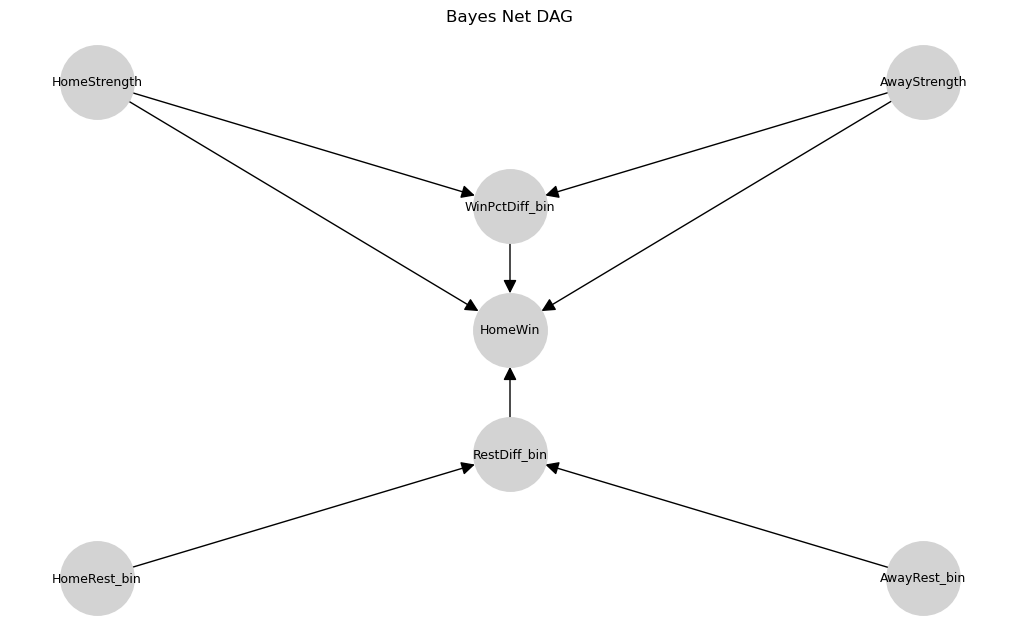

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
nodes = ["HomeWin", "HomeStrength","AwayStrength", "WinPctDiff_bin", "HomeRest_bin", "AwayRest_bin", "RestDiff_bin"]

G.add_nodes_from(nodes)

G.add_edge("HomeStrength", "WinPctDiff_bin")
G.add_edge("AwayStrength", "WinPctDiff_bin")
G.add_edge("HomeStrength", "HomeWin")
G.add_edge("AwayStrength", "HomeWin")
G.add_edge("HomeRest_bin", "RestDiff_bin")
G.add_edge("AwayRest_bin", "RestDiff_bin")
G.add_edge("WinPctDiff_bin", "HomeWin")
G.add_edge("RestDiff_bin", "HomeWin")

pos = {
    "HomeStrength": (-2, 1),
    "AwayStrength": (2, 1),
    "WinPctDiff_bin": (0, 0.5),
    "HomeRest_bin": (-2, -1),
    "AwayRest_bin": (2, -1),
    "RestDiff_bin": (0, -0.5),
    "HomeWin": (0, 0)
}

plt.figure(figsize=(10, 6))
nx.draw(G, pos, with_labels=True, node_size=2800, node_color="lightgray", font_size=9, arrowsize=20)
plt.title("Bayes Net DAG")
plt.show()

## Parameter Learning (MLE for CPT's)

CPT's were estimated with Maximum Likelihood Estimation on the training data. For each node, empirical counts of the node and its parent were computed and normalized to obtain conditional probabilities. Root node CPTs were estimated as marginal distributions, while non-root CPTs were estimated as conditional frequencies given their parents.

In [17]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(data, test_size=0.2, random_state=42, stratify=data["HomeWin"])


In [18]:
def compute_cpt(df, child, parents):
    if not parents:
        counts = (
            df[child]
            .value_counts()
            .sort_index()
            .reset_index()
        )
        counts.columns = [child, "count"]

        counts["P"] = counts["count"] / counts["count"].sum()

        return counts[[child, "P"]]

    counts = (
        df
        .groupby(parents + [child])
        .size()
        .reset_index(name="count")
    )

    counts["P"] = counts.groupby(parents)["count"].transform(
        lambda x: x / x.sum()
    )

    return counts[parents + [child, "P"]]


In [19]:
cpt_home_strength = compute_cpt(df_train, "HomeStrength", [])
cpt_away_strength = compute_cpt(df_train, "AwayStrength", [])
cpt_home_rest = compute_cpt(df_train, "HomeRest_bin", [])
cpt_away_rest = compute_cpt(df_train, "AwayRest_bin", [])


In [20]:
cpt_winpct_diff = compute_cpt(df_train, "WinPctDiff_bin", ["HomeStrength", "AwayStrength"])
cpt_rest_diff = compute_cpt(df_train, "RestDiff_bin", ["HomeRest_bin", "AwayRest_bin"])
cpt_homewin = compute_cpt(df_train, "HomeWin", ["WinPctDiff_bin", "RestDiff_bin"])

/var/folders/4n/gr221w3n74g83smf7w9pzfy00000gn/T/ipykernel_56750/773807723.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(parents + [child])
/var/folders/4n/gr221w3n74g83smf7w9pzfy00000gn/T/ipykernel_56750/773807723.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(parents + [child])
/var/folders/4n/gr221w3n74g83smf7w9pzfy00000gn/T/ipykernel_56750/773807723.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence 

In [21]:
cpt_home_strength

,HomeStrength,P
0,Average,0.396971
1,Strong,0.320224
2,Weak,0.282805


In [22]:
cpt_away_strength

,AwayStrength,P
0,Average,0.399720
1,Strong,0.307036
2,Weak,0.293243


In [23]:
cpt_home_rest

,HomeRest_bin,P
0,BackToBack,0.007829
1,NormalRest,0.721202
2,WellRested,0.270969


In [24]:
cpt_away_rest

,AwayRest_bin,P
0,BackToBack,0.007829
1,NormalRest,0.776002
2,WellRested,0.216170


In [25]:
cpt_winpct_diff.sort_values(["HomeStrength", "AwayStrength", "WinPctDiff_bin"])

,HomeStrength,AwayStrength,WinPctDiff_bin,P
0,Average,Average,AwayStronger,0.102030
1,Average,Average,Even,0.785244
2,Average,Average,HomeStronger,0.112726
3,Average,Strong,AwayStronger,0.846463
4,Average,Strong,Even,0.153537
5,Average,Strong,HomeStronger,0.000000
6,Average,Weak,AwayStronger,0.000000
7,Average,Weak,Even,0.123270
8,Average,Weak,HomeStronger,0.876730
9,Strong,Average,AwayStronger,0.000000


In [26]:
cpt_rest_diff.sort_values(["HomeRest_bin", "AwayRest_bin", "RestDiff_bin"])

,HomeRest_bin,AwayRest_bin,RestDiff_bin,P
0,BackToBack,BackToBack,AwayRestAdv,0.000000
1,BackToBack,BackToBack,EvenRest,1.000000
2,BackToBack,BackToBack,HomeRestAdv,0.000000
3,BackToBack,NormalRest,AwayRestAdv,NaN
4,BackToBack,NormalRest,EvenRest,NaN
5,BackToBack,NormalRest,HomeRestAdv,NaN
6,BackToBack,WellRested,AwayRestAdv,NaN
7,BackToBack,WellRested,EvenRest,NaN
8,BackToBack,WellRested,HomeRestAdv,NaN
9,NormalRest,BackToBack,AwayRestAdv,NaN


In [27]:
cpt_homewin.sort_values(["WinPctDiff_bin", "RestDiff_bin", "HomeWin"])


,WinPctDiff_bin,RestDiff_bin,HomeWin,P
0,AwayStronger,AwayRestAdv,0,0.752705
1,AwayStronger,AwayRestAdv,1,0.247295
2,AwayStronger,EvenRest,0,0.700759
3,AwayStronger,EvenRest,1,0.299241
4,AwayStronger,HomeRestAdv,0,0.688879
5,AwayStronger,HomeRestAdv,1,0.311121
6,Even,AwayRestAdv,0,0.433036
7,Even,AwayRestAdv,1,0.566964
8,Even,EvenRest,0,0.398381
9,Even,EvenRest,1,0.601619


## Inference on Test Set

In [28]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination

cols = ["HomeWin", "HomeStrength", "AwayStrength", "WinPctDiff_bin", "HomeRest_bin", "AwayRest_bin", "RestDiff_bin"]

model = DiscreteBayesianNetwork([
    ("HomeStrength", "WinPctDiff_bin"),
    ("AwayStrength", "WinPctDiff_bin"),
    ("HomeStrength", "HomeWin"),
    ("AwayStrength", "HomeWin"),
    ("HomeRest_bin", "RestDiff_bin"),
    ("AwayRest_bin", "RestDiff_bin"),
    ("WinPctDiff_bin", "HomeWin"),
    ("RestDiff_bin", "HomeWin")
])

model.fit(df_train, estimator=MaximumLikelihoodEstimator)

infer = VariableElimination(model)

# Example queries
query1 = infer.query(
    variables=["HomeWin"],
    evidence={"HomeStrength": "Strong", "AwayStrength": "Weak"}
)
print("Query 1: P(HomeWin | HomeStrength=Strong, AwayStrength=Weak)")
print(query1, "\n")

query2 = infer.query(
    variables=["HomeWin"],
    evidence={"WinPctDiff_bin": "HomeStronger", "RestDiff_bin": "HomeRestAdv"}
)
print("Query 2: P(HomeWin | WinPctDiff_bin=HomeStronger, RestDiff_bin=HomeRestAdv)")
print(query2, "\n")

query3 = infer.query(
    variables=["HomeWin"],
    evidence={"HomeStrength": "Average", "AwayStrength": "Average", "RestDiff_bin": "EvenRest"}
)
print("Query 3: P(HomeWin | HomeStrength=Average, AwayStrength=Average, RestDiff_bin=EvenRest)")
print(query3, "\n")

evidence_columns = ["HomeStrength", "AwayStrength", "WinPctDiff_bin", "RestDiff_bin"]

df_test["Predicted_HomeWin"] = model.predict(df_test[evidence_columns])["HomeWin"]

print(df_test[["HomeWin", "Predicted_HomeWin"]].head(10))


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'HomeWin': 'N', 'HomeStrength': 'C', 'AwayStrength': 'C', 'WinPctDiff_bin': 'O', 'HomeRest_bin': 'C', 'AwayRest_bin': 'C', 'RestDiff_bin': 'O'}


Query 1: P(HomeWin | HomeStrength=Strong, AwayStrength=Weak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.0747 |
+------------+----------------+
| HomeWin(1) |         0.9253 |
+------------+----------------+ 

Query 2: P(HomeWin | WinPctDiff_bin=HomeStronger, RestDiff_bin=HomeRestAdv)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.1299 |
+------------+----------------+
| HomeWin(1) |         0.8701 |
+------------+----------------+ 

Query 3: P(HomeWin | HomeStrength=Average, AwayStrength=Average, RestDiff_bin=EvenRest)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.3952 |
+------------+----------------+
| HomeWin(1) |         0.6048 |
+------------+----------------+ 



/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(
/Users/leowiemelt/anaconda3/lib/python3.11/site-packages/pgmpy/models/DiscreteBayesianNetwork.py:720: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data_unique_indexes = data.groupby(list(data.columns), dropna=False).apply(


  0%|          | 0/57 [00:00<?, ?it/s]

       HomeWin  Predicted_HomeWin
12441        0                  1
24194        1                  1
25195        0                  0
25879        1                  1
26011        1                  1
14549        1                  1
13774        1                  1
3948         1                  1
21977        0                  1
18120        1                  1


## Evaluation Metrics

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = df_test["HomeWin"]
y_pred = df_test["Predicted_HomeWin"]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, pos_label=1)
recall = recall_score(y_true, y_pred, pos_label=1)
f1 = f1_score(y_true, y_pred, pos_label=1)

print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}\n")

Evaluation Metrics:
Accuracy: 72.23%
Precision: 73.24%
Recall: 83.01%
F1-score: 77.82%



### Interpretation
Overall, the model is more likely to catch actual wins than it is to avoid false positives. For using fairly basic inputs, the model can predict a good proportion of home wins, though it tends to overpredict them.